<a href="https://colab.research.google.com/github/Crisstudy/Aplicacao-de-Ciencia-de-Dados-para-Negocios/blob/main/CRM_ANALITICO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CONSTRUINDO UMA SOLUCAO DE CRM ANALITICO

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from matplotlib.colors import ListedColormap

In [30]:
!gdown 1Zaclyhh9oYWHDMq3gEHKJRcgB0GD9lT5

Downloading...
From: https://drive.google.com/uc?id=1Zaclyhh9oYWHDMq3gEHKJRcgB0GD9lT5
To: /content/Wine.csv
100% 11.5k/11.5k [00:00<00:00, 20.8MB/s]


In [31]:
df = pd.read_csv('Wine.csv')

In [32]:
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [33]:
X = df.iloc[:, 0:13].values
y = df.iloc[:, 13].values

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state= 0)


In [35]:
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [36]:
pca = PCA(n_components= 2)

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

explaned_variance = pca.explained_variance_ratio_

In [37]:
calssifier = LogisticRegression(random_state= 0)
calssifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [38]:
y_pred = calssifier.predict(X_test)

In [39]:
cm = confusion_matrix(y_test, y_pred)

/tmp/ipykernel_4836/3637530500.py:15: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


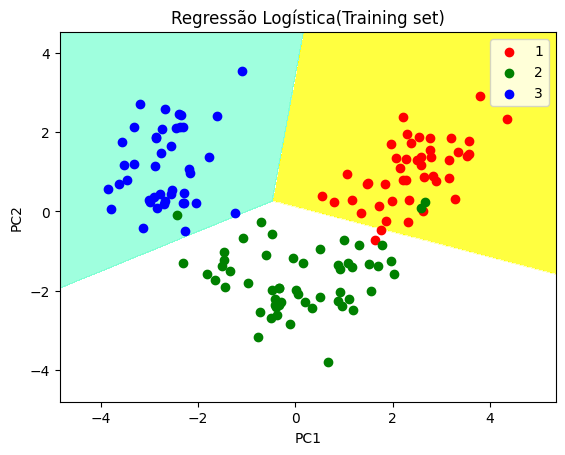

In [40]:
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1,
                     stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1,
                     stop = X_set[:, 1].max() + 1, step = 0.01))

plt.contourf(X1, X2, calssifier.predict(np.array([X1.ravel(),
             X2.ravel()]).T).reshape(X1.shape), alpha = 0.75,
             cmap = ListedColormap(('yellow', 'white', 'aquamarine')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
              c = ListedColormap(('red', 'green', 'blue'))(i), label = j)

plt.title('Regressão Logística(Training set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()

plt.show()

/tmp/ipykernel_4836/1439671345.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


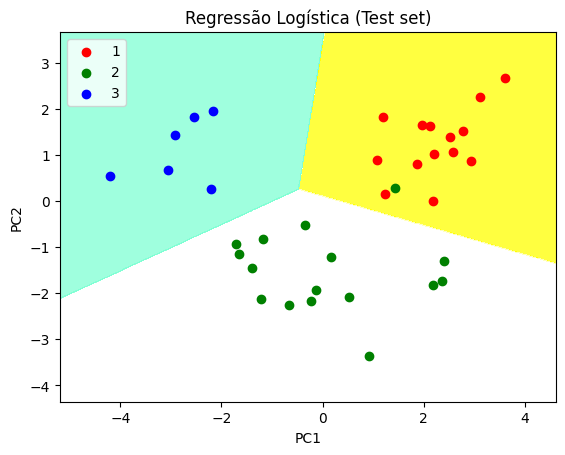

In [41]:
X_set, y_set = X_test, y_test

X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1,
                     stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1,
                     stop = X_set[:, 1].max() + 1, step = 0.01))

plt.contourf(X1, X2, calssifier.predict(np.array([X1.ravel(),
             X2.ravel()]).T).reshape(X1.shape), alpha = 0.75,
             cmap = ListedColormap(('yellow', 'white', 'aquamarine')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)

plt.title('Regressão Logística (Test set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()


plt.show()

In [44]:

X = df.drop('Customer_Segment', axis=1)
y = df['Customer_Segment']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(len(X.columns))],index=X.columns)

print(loadings)

                           PC1       PC2  ...      PC12      PC13
Alcohol               0.144329  0.483652  ... -0.266286  0.014970
Malic_Acid           -0.245188  0.224931  ...  0.121696  0.025964
Ash                  -0.002051  0.316069  ... -0.049622 -0.141218
Ash_Alcanity         -0.239320 -0.010591  ... -0.055743  0.091683
Magnesium             0.141992  0.299634  ...  0.062220  0.056774
Total_Phenols         0.394661  0.065040  ... -0.303882 -0.463908
Flavanoids            0.422934 -0.003360  ... -0.042899  0.832257
Nonflavanoid_Phenols -0.298533  0.028779  ...  0.042352  0.114040
Proanthocyanins       0.313429  0.039302  ... -0.095553 -0.116917
Color_Intensity      -0.088617  0.529996  ...  0.604222 -0.011993
Hue                   0.296715 -0.279235  ...  0.259214 -0.089889
OD280                 0.376167 -0.164496  ...  0.600959 -0.156718
Proline               0.286752  0.364903  ... -0.079402  0.014447

[13 rows x 13 columns]
